# [6.3] Feature Splitting, Absorption and Dashboards (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter6_sparse_feature_methods/exercises/part3_sae_pathologies_dashboards/6.3_Feature_Splitting_Absorption_and_Dashboards_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter6_sparse_feature_methods/exercises/part3_sae_pathologies_dashboards/6.3_Feature_Splitting_Absorption_and_Dashboards_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

A dashboard shows `apricot`, `ant` and `avocado` as top examples for an “starts with A” feature. Its precision is perfect. Yet the feature does not activate on `apple`. Has the model forgotten how to spell apple, or has the dictionary put that information somewhere else?

By the end of this notebook, you will have shown on an exact first-letter task that a wider sparse dictionary can reconstruct every activation while a plausible named feature misses a positive example. A coverage audit and error-preserving ablation will locate the missing contribution; a shuffled-label baseline and unrelated-feature ablation will test the dashboard story.

The organism is deliberately explicit. Word properties are known, the decoder is supplied, and no SAE training is hidden in a helper. We compare a width-two dictionary with a width-three dictionary to demonstrate a possible failure mode, not a learned scaling law. The arithmetic mirrors the first-letter investigation in Chanin et al.; it does not reproduce their trained language-model experiment.

Prerequisites: [6.1] sparse encoding/decoding and [1.2] residual-stream interventions. For the attention-output part, remember that concatenated head outputs precede `W_O`. A feature can mix several heads, and an encoder-direction attribution is not a causal claim about a head.

**Study edition:** the default examples are deterministic CPU teaching fixtures. No pretrained model is loaded, no network is used, and no trained-model benchmark or native qualification is claimed. Save a personal copy.

## Content & Learning Objectives

### 1️⃣ When a good reconstruction hides a concept

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 2️⃣ Measure coverage, not just top examples

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 3️⃣ Attribute and ablate attention-output features

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 4️⃣ Build a dashboard that can be wrong

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### ☆ Bonus

Predict a changed condition, inspect an anomaly, and plan the paper-to-model bridge.

## Setup code

In [1]:
from pathlib import Path
import sys
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

chapter = "chapter6_sparse_feature_methods"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part3_sae_pathologies_dashboards.tests as tests

MAIN = __name__ == "__main__"
# NumPy arrays stay on CPU; float64 makes small analytic comparisons transparent.

# 1️⃣ When a good reconstruction hides a concept

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

Each row represents a word with four observable coordinates: `[starts_with_a, starts_with_b, is_apple, nuisance]`. The nuisance coordinate is zero in the frozen core fixture. The model's first-letter logits read only the first two coordinates; the third records a word-specific property. Our eight words are apple, apricot, ant, avocado, banana, berry, boat and bean. These are public development illustrations, not a held-out language corpus.

A sparse dictionary reconstructs $\hat x=zD+b_D$ from nonnegative codes $z=\operatorname{ReLU}(xE+b_E)$. We use zero biases. The narrow dictionary decodes only A and B. The wider dictionary offers a general A direction, a B direction, and an apple-specific direction containing **both** A and apple coordinates. Its general A encoder subtracts the apple coordinate. Thus apple can be reconstructed without firing the feature we named A.

Do not infer the “true number of concepts” from dictionary width. The dictionaries differ in both basis and encoding rule, and the supplied construction was selected to expose a mechanism. A trained width/sparsity comparison would require frozen training data, optimization budgets, matched evaluation, multiple seeds and a selection policy. Those measurements remain pending.

### Exercise - implement `word_properties`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return an `(n,4)` float array in the exact coordinate order above. Use case-insensitive first letters and exact lowercased equality for apple. The fourth coordinate is zero. Reject empty strings, whose first letter is undefined. This is the visible data-generating mechanism: the task is about first-letter representations, not an unrelated random feature cloud.

In [2]:
def word_properties(words):
    """Return explicit first-letter/identity coordinates for benign words."""
    if any(not word for word in words):
        raise ValueError("Every example needs a word")
    return np.array([[w.lower().startswith("a"),w.lower().startswith("b"),w.lower()=="apple",0.] for w in words],dtype=float).reshape(len(words),4)


tests.test_word_properties(word_properties)

All tests in test_word_properties passed!


<details>
<summary>Hint</summary>

Distinguish the spelling property from the identity property. `applejack` starts with A but is not exactly apple.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_word_properties passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `encode_relu`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute `maximum(x @ encoder + bias, 0)`. The encoder is `(input,features)`, while the decoder later has `(features,input)`; they are not transposes by definition. A negative encoder weight can suppress a broad feature when a specific property is present. Preserve example order and do not normalize activations: precision, coverage and intervention magnitudes depend on that scale.

In [3]:
def encode_relu(x, encoder, bias):
    """Encode `(examples,input)` into nonnegative `(examples,features)` codes."""
    return np.maximum(x@encoder+bias,0)


tests.test_encode_relu(encode_relu)

All tests in test_encode_relu passed!


<details>
<summary>Hint</summary>

The subtraction happens before the ReLU. Applying ReLU to weights individually erases the very suppression we want to inspect.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_encode_relu passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `decode_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `codes @ decoder + bias`. For a single active feature, changing its activation by one should add exactly one decoder row. Keep the decoder bias separate: a feature ablation should not remove the bias. The row-wise convention will also determine the sign and shape of logit effects later.

In [4]:
def decode_features(codes, decoder, bias):
    """Reconstruct activations from codes and row-wise decoder directions."""
    return codes@decoder+bias


tests.test_decode_features(decode_features)

All tests in test_decode_features passed!


<details>
<summary>Hint</summary>

Codes weight decoder rows. A bias is broadcast once per example, not once per active feature.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_decode_features passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `reconstruction_mse`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Use the full `(examples,input)` denominator, not only examples with active features. Reject shape mismatches and empty arrays. Reconstruction error measures what is lost in activation space. It does not certify that the named features cover the concept of interest: a word-specific feature can reconstruct a broad property perfectly.

In [5]:
def reconstruction_mse(x, reconstructed):
    """Mean squared error over all examples and all coordinates."""
    if x.shape!=reconstructed.shape or x.size==0:
        raise ValueError("Need nonempty matching activation arrays")
    return float(np.mean((x-reconstructed)**2))


tests.test_reconstruction_mse(reconstruction_mse)

All tests in test_reconstruction_mse passed!


<details>
<summary>Hint</summary>

There are six coordinates in the hand fixture, even though only one has an error.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_reconstruction_mse passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

In [6]:
WORDS=["apple","apricot","ant","avocado","banana","berry","boat","bean"]
X=word_properties(WORDS)
E_narrow=np.array([[1.,0.],[0.,1.],[0.,0.],[0.,0.]])
D_narrow=np.array([[1.,0.,0.,0.],[0.,1.,0.,0.]])
E_wide=np.array([[1.,0.,0.],[0.,1.,0.],[-1.,0.,1.],[0.,0.,0.]])
D_wide=np.array([[1.,0.,0.,0.],[0.,1.,0.,0.],[1.,0.,1.,0.]])
Z_narrow=encode_relu(X,E_narrow,np.zeros(2));Z_wide=encode_relu(X,E_wide,np.zeros(3))
W_U=np.array([[1.,0.],[0.,1.],[0.,0.],[0.,0.]])
labels=X[:,0].astype(bool)

## A wider dictionary reconstructs more, but names less

,word,A concept,narrow A,wide general A,wide apple
0,apple,True,1.0,0.0,1.0
1,apricot,True,1.0,1.0,0.0
2,ant,True,1.0,1.0,0.0
3,avocado,True,1.0,1.0,0.0
4,banana,False,0.0,0.0,0.0
5,berry,False,0.0,0.0,0.0
6,boat,False,0.0,0.0,0.0
7,bean,False,0.0,0.0,0.0


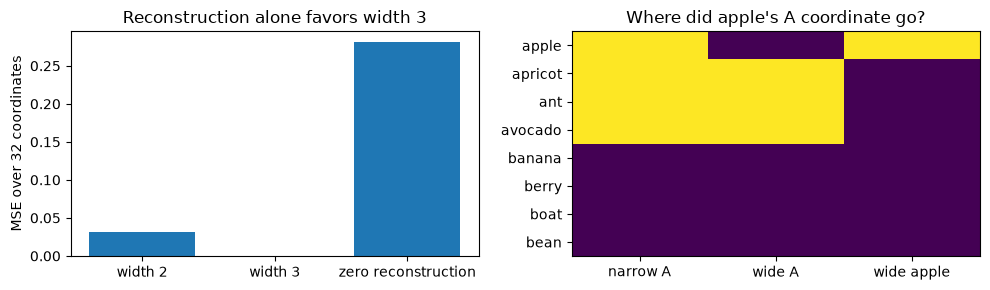

MSE narrow/wide/zero [0.03125, 0.0, 0.28125]


In [7]:
errors=[reconstruction_mse(X,decode_features(Z_narrow,D_narrow,np.zeros(4))),reconstruction_mse(X,decode_features(Z_wide,D_wide,np.zeros(4))),reconstruction_mse(X,np.zeros_like(X))]
display(pd.DataFrame({"word":WORDS,"A concept":labels,"narrow A":Z_narrow[:,0],"wide general A":Z_wide[:,0],"wide apple":Z_wide[:,2]}))
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].bar(["width 2","width 3","zero reconstruction"],errors);axes[0].set(ylabel="MSE over 32 coordinates",title="Reconstruction alone favors width 3")
axes[1].imshow(np.c_[Z_narrow[:,0],Z_wide[:,0],Z_wide[:,2]],aspect="auto",vmin=0,vmax=1);axes[1].set(xticks=range(3),xticklabels=["narrow A","wide A","wide apple"],yticks=range(8),yticklabels=WORDS,title="Where did apple's A coordinate go?")
fig.tight_layout();plt.show();print("MSE narrow/wide/zero",errors)

<details>
<summary>Help - how should I interpret this?</summary>

The narrow reconstruction misses the apple identity coordinate: its MSE is 1/32. The wider reconstruction is exact. Yet the wide general-A code is zero on apple. The table shows that a single-feature dashboard can become less complete while reconstruction improves. The all-zero reconstruction is the reference failure, not a trained competing dictionary.

</details>

## Summary of 1️⃣

Reconstruction and concept coverage are distinct measurements. The dictionary can represent a broad property through a specific feature, so naming only its broad feature is incomplete.

# 2️⃣ Measure coverage, not just top examples

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

A top-examples panel asks “what do active examples have in common?” Precision answers a similar conditional question: $P(A\mid z_j>\theta)$. Recall reverses it: $P(z_j>\theta\mid A)$. Our general-A feature has perfect precision but misses apple, so its recall is three quarters. This is the simplest reason to inspect the denominator before celebrating a dashboard label.

To diagnose splitting, compare active-example sets across dictionaries. Jaccard overlap is intersection over union; it can reveal a broad feature distributing into narrower pieces. But overlap alone is neither decoder equivalence nor proof of absorption. A more specific diagnostic flags a known-positive example where the named feature is inactive but an alternate feature fires. Then a causal check must ask whether the alternate feature actually carries the missing task contribution. We will perform that check in part 3.

The thresholds and candidate set are fixed before computing these tables. Searching many thresholds or alternative features and reporting only a good-looking one would be selection. Randomizing labels tests the meaning attached to an activation pattern; it does not change the reconstruction or make the shuffled set a guaranteed zero-overlap null.

### Exercise - implement `top_examples`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the first `k` indices of a stable descending sort of a one-dimensional activation vector. Reject negative k and cap it at the cohort size. Do not discard zeros silently: a dashboard should say whether it ran out of active examples. Stable ties preserve original example order and make exported panels recoverable.

In [8]:
def top_examples(activations, k=5):
    """Stable descending example indices, retaining deterministic ties."""
    if k<0 or np.asarray(activations).ndim!=1:
        raise ValueError("Expected a vector and nonnegative k")
    return np.argsort(-np.asarray(activations),kind="stable")[:k]


tests.test_top_examples(top_examples)

All tests in test_top_examples passed!


<details>
<summary>Hint</summary>

Sort the negative activations with a stable algorithm. Reversing an ascending sort reverses ties too.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_top_examples passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `precision_recall`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Treat activations strictly above the threshold as firing. Return `(precision, recall)`; define precision as zero when no feature fires and recall as zero when there are no positives. These are declared descriptive conventions, not confidence intervals. The tests distinguish a feature that never fires from a perfect detector.

In [9]:
def precision_recall(activations, concept, threshold=0.0):
    """Concept precision and recall with explicit inactive-set behavior."""
    active=np.asarray(activations)>threshold;positive=np.asarray(concept,dtype=bool)
    if active.shape!=positive.shape:
        raise ValueError("Activation and concept axes must match")
    tp=np.count_nonzero(active&positive)
    return (float(tp/active.sum()) if active.any() else 0.,float(tp/positive.sum()) if positive.any() else 0.)


tests.test_precision_recall(precision_recall)

All tests in test_precision_recall passed!


<details>
<summary>Hint</summary>

Count the intersection once, then divide by two different denominators. Threshold equality is inactive.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_precision_recall passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `activation_overlap`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`left` is `(examples,left_features)` and `right` `(examples,right_features)`. Return `(left_features,right_features)` intersection-over-union scores. Define an empty/empty pair as zero so two dead features do not appear meaningfully aligned. This is an activity-based diagnostic; a high overlap can still hide different decoder signs or intervention effects.

In [10]:
def activation_overlap(left, right, threshold=0.0):
    """Pairwise Jaccard overlap of active example sets."""
    a=left>threshold;b=right>threshold
    intersection=a.astype(int).T@b.astype(int)
    union=a.sum(0)[:,None]+b.sum(0)[None,:]-intersection
    return np.divide(intersection,union,out=np.zeros_like(intersection,dtype=float),where=union>0)


tests.test_activation_overlap(activation_overlap)

All tests in test_activation_overlap passed!


<details>
<summary>Hint</summary>

An integer matrix product counts intersections. Boolean matrix multiplication can give Boolean rather than count semantics.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_activation_overlap passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `absorption_candidates`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return an example mask of `concept & primary_inactive & any_alternate_active`. `alternatives` has shape `(examples,features)` and may have zero columns. This is a candidate detector only. It cannot know whether the alternate code reconstructs the concept; decoder directions and interventions decide that. Keep the word candidate in the function's interpretation.

In [11]:
def absorption_candidates(concept, primary, alternatives, threshold=0.0):
    """Flag positives missed by primary but active in any alternate feature."""
    return np.asarray(concept,dtype=bool)&(primary<=threshold)&np.any(alternatives>threshold,axis=1)


tests.test_absorption_candidates(absorption_candidates)

All tests in test_absorption_candidates passed!


<details>
<summary>Hint</summary>

Require all three conditions. An inactive positive with no active alternative is a miss, but not an absorption candidate under this diagnostic.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_absorption_candidates passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

## Audit the dashboard label

,word,candidate,general A,apple alternative
0,apple,True,0.0,1.0
1,apricot,False,1.0,0.0
2,ant,False,1.0,0.0
3,avocado,False,1.0,0.0
4,banana,False,0.0,0.0
5,berry,False,0.0,0.0
6,boat,False,0.0,0.0
7,bean,False,0.0,0.0


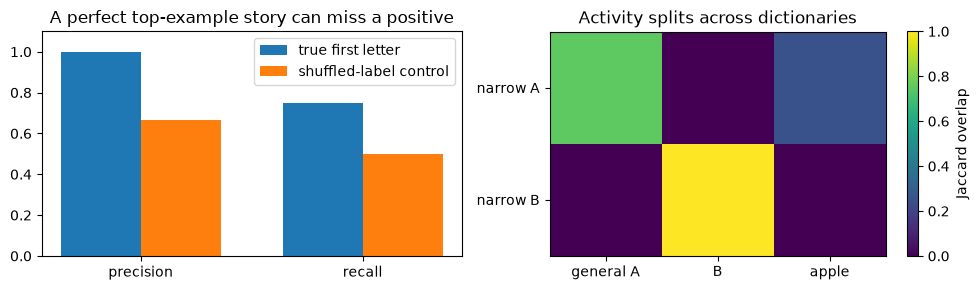

precision/recall (1.0, 0.75) shuffled (0.6666666666666666, 0.5)


In [12]:
precision,recall=precision_recall(Z_wide[:,0],labels)
shuffled=np.random.default_rng(3).permutation(labels)
control=precision_recall(Z_wide[:,0],shuffled)
candidates=absorption_candidates(labels,Z_wide[:,0],Z_wide[:,[1,2]])
display(pd.DataFrame({"word":WORDS,"candidate":candidates,"general A":Z_wide[:,0],"apple alternative":Z_wide[:,2]}))
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].bar(np.arange(2)-.18,[precision,recall],.36,label="true first letter");axes[0].bar(np.arange(2)+.18,control,.36,label="shuffled-label control");axes[0].set(xticks=[0,1],xticklabels=["precision","recall"],ylim=(0,1.1),title="A perfect top-example story can miss a positive");axes[0].legend()
im=axes[1].imshow(activation_overlap(Z_narrow,Z_wide),vmin=0,vmax=1);axes[1].set(xticks=range(3),xticklabels=["general A","B","apple"],yticks=range(2),yticklabels=["narrow A","narrow B"],title="Activity splits across dictionaries");fig.colorbar(im,ax=axes[1],label="Jaccard overlap")
fig.tight_layout();plt.show();print("precision/recall",(precision,recall),"shuffled",control)

<details>
<summary>Help - how should I interpret this?</summary>

General A has precision 1 and recall 0.75 on four A words. Apple is the sole flagged candidate; the next part tests whether its alternative feature really carries A. The shuffle may retain nonzero precision because it keeps four positive labels. Jaccard overlap partitions the narrow A activity across general A and apple; it is descriptive alignment, not a learned feature matching guarantee.

</details>

## Summary of 2️⃣

Top examples support a precision story; known positives reveal recall failures. Splitting and absorption diagnostics propose a causal question rather than resolving it.

# 3️⃣ Attribute and ablate attention-output features

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

Suppose `x` is the concatenation of two attention-head outputs, each with two channels. For an encoder direction $e_j$, the preactivation is $\sum_h z_h^\top e_{j,h}+b_j$. A negative contribution from one head can cancel a positive contribution from another before ReLU. This is why a head label is a poor substitute for inspecting features across heads.

For a decoder direction in concatenated head space, its direct logit effect travels through the actual head output projection: $d_{j,h}W_O^{h}W_U$. Do not treat concatenated `hook_z` coordinates as residual-stream coordinates unless the projection is explicitly identity. Our core fixture uses identity routing only to make the arithmetic exact and inspectable.

For a causal feature removal at the represented activation site, preserve the reconstruction error $e=x-\hat x$. Replacing the whole activation by a decoded reconstruction changes both the chosen feature and that error. Instead use $x'=x-z_jD_j$, or subtract several selected feature contributions together. This intervention has a clear algebraic meaning but can still be off-manifold; its specificity must be checked on actual task outputs and unrelated features.

### Exercise - implement `head_preactivation_contributions`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`head_outputs` is `(examples,heads,head_dim)` and `encoder` `(heads*head_dim,features)`. Reshape the encoder to `(heads,head_dim,features)` and sum within each head, returning `(examples,heads,features)`. Summing over heads reproduces the bias-free encoder preactivation. These signed terms are a coordinate decomposition, not attention probabilities.

In [13]:
def head_preactivation_contributions(head_outputs, encoder):
    """Per-head contributions to encoder preactivations before bias/ReLU."""
    n,h,d=head_outputs.shape
    return np.einsum("nhd,hdf->nhf",head_outputs,encoder.reshape(h,d,-1))


tests.test_head_preactivation_contributions(head_preactivation_contributions)

All tests in test_head_preactivation_contributions passed!


<details>
<summary>Hint</summary>

Keep the head axis. Summing it too early hides cancellation between heads.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_head_preactivation_contributions passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `head_decoder_logit_effects`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`decoder` is `(features,heads*head_dim)`, `W_O` `(heads,head_dim,residual)` and `W_U` `(residual,vocab)`. Return `(features,heads,vocab)`. This is the direct linear effect of adding one unit of a decoder direction, before any later nonlinear computation. It is neither the encoder attribution above nor a full causal language-model prediction.

In [14]:
def head_decoder_logit_effects(decoder, W_O, W_U):
    """Map each feature/head decoder slice through output and unembedding."""
    h,d,r=W_O.shape
    return np.einsum("fhd,hdr,rv->fhv",decoder.reshape(len(decoder),h,d),W_O,W_U)


tests.test_head_decoder_logit_effects(head_decoder_logit_effects)

All tests in test_head_decoder_logit_effects passed!


<details>
<summary>Hint</summary>

The output projection has a head-specific slice. Passing `decoder @ W_U` directly is dimensionally wrong for non-identity `W_O`.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_head_decoder_logit_effects passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `ablate_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a new activation array with selected feature contributions removed. Require unique, in-range indices so a repeated index cannot double an ablation. An empty set is an identity. The error-preserving convention is `x - codes[:,indices] @ decoder[indices]`; it remains meaningful even when the dictionary reconstructs poorly. Do not silently switch to `(all other codes) @ decoder`.

In [15]:
def ablate_features(x, codes, decoder, indices):
    """Subtract selected decoded features while retaining reconstruction error."""
    indices=list(indices)
    if len(set(indices))!=len(indices) or any(i<0 or i>=codes.shape[1] for i in indices):
        raise ValueError("Unique valid feature indices required")
    return np.array(x,copy=True)-codes[:,indices]@decoder[indices]


tests.test_ablate_features(ablate_features)

All tests in test_ablate_features passed!


<details>
<summary>Hint</summary>

The fixture deliberately includes reconstruction error. The untouched coordinate must stay at seven rather than dropping to its decoded value of two.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_ablate_features passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `correct_class_margin`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return one margin per example, not an already averaged scalar. `logits` is `(examples,2)` and `class_ids` is zero for A, one for B. The A-word ablation plot will use the exact four A words as its denominator, so removing B is an unrelated-feature control there. A score aggregated over all words would answer a different specificity question.

In [16]:
def correct_class_margin(logits, class_ids):
    """Per-example correct-minus-other margin for a two-class task."""
    ids=np.asarray(class_ids,dtype=int)
    if logits.shape!=(len(ids),2) or np.any((ids<0)|(ids>1)):
        raise ValueError("Expected valid two-class logits")
    return logits[np.arange(len(ids)),ids]-logits[np.arange(len(ids)),1-ids]


tests.test_correct_class_margin(correct_class_margin)

All tests in test_correct_class_margin passed!


<details>
<summary>Hint</summary>

Subtract the competitor for each row. A correct positive margin and top-1 accuracy are related but not identical under ties.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_correct_class_margin passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

## Signature result — find the missing causal contribution

,no edit,general A only,apple only,A plus apple,unrelated B control
apple,0.0,0.0,1.0,1.0,0.0
apricot,0.0,1.0,0.0,1.0,0.0
ant,0.0,1.0,0.0,1.0,0.0
avocado,0.0,1.0,0.0,1.0,0.0
banana,0.0,0.0,0.0,0.0,1.0
berry,0.0,0.0,0.0,0.0,1.0
boat,0.0,0.0,0.0,0.0,1.0
bean,0.0,0.0,0.0,0.0,1.0


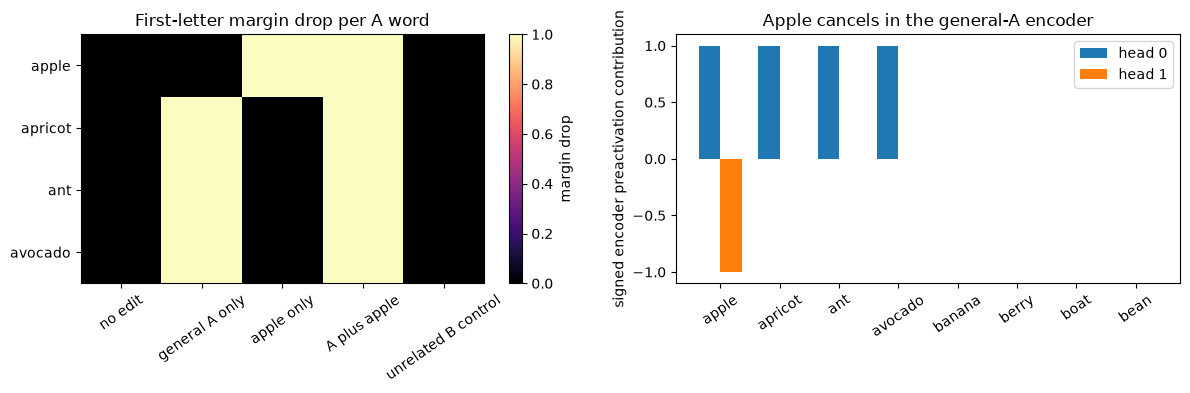

mean A-word margin drops {'no edit': 0.0, 'general A only': 0.75, 'apple only': 0.25, 'A plus apple': 1.0, 'unrelated B control': 0.0}


In [17]:
conditions={"no edit":[],"general A only":[0],"apple only":[2],"A plus apple":[0,2],"unrelated B control":[1]}
class_ids=np.where(labels,0,1)
effects={}
for name,ids in conditions.items():
    edited=ablate_features(X,Z_wide,D_wide,ids)
    effects[name]=correct_class_margin(X@W_U,class_ids)-correct_class_margin(edited@W_U,class_ids)
display(pd.DataFrame(effects,index=WORDS))
fig,axes=plt.subplots(1,2,figsize=(12,4))
matrix=np.stack([effects[name][labels] for name in conditions],axis=1)
im=axes[0].imshow(matrix,aspect="auto",vmin=0,vmax=1,cmap="magma");axes[0].set(xticks=range(5),xticklabels=list(conditions),yticks=range(4),yticklabels=np.array(WORDS)[labels],title="First-letter margin drop per A word");axes[0].tick_params(axis="x",rotation=35);fig.colorbar(im,ax=axes[0],label="margin drop")
contributions=head_preactivation_contributions(X.reshape(8,2,2),E_wide)
axes[1].bar(np.arange(8)-.18,contributions[:,0,0],.36,label="head 0");axes[1].bar(np.arange(8)+.18,contributions[:,1,0],.36,label="head 1");axes[1].set(xticks=range(8),xticklabels=WORDS,ylabel="signed encoder preactivation contribution",title="Apple cancels in the general-A encoder");axes[1].tick_params(axis="x",rotation=35);axes[1].legend();fig.tight_layout();plt.show()
print("mean A-word margin drops",{name:float(value[labels].mean()) for name,value in effects.items()})

<details>
<summary>Help - how should I interpret this?</summary>

Removing general A leaves apple unchanged but drops each other A word by one. Removing apple does the reverse; removing both drops every A word by one. Removing unrelated B leaves all A words unchanged. The head panel explains why the broad code is absent on apple: +1 and −1 cancel before ReLU. This exact dictionary counterexample validates the local dashboard diagnosis, not a population prevalence of absorption in trained SAEs.

</details>

## Summary of 3️⃣

Signed encoder contributions, decoder-to-logit effects and actual ablations answer different questions. Preserve the reconstruction error and compare the same examples under each edit.

# 4️⃣ Build a dashboard that can be wrong

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

A useful feature dashboard is a compact argument: an activity distribution, examples supporting a label, task logit effects, and an intervention that could falsify that label. We will export the public example records with their exact activations and carry precision/recall beside them. A consumer should not have to infer coverage from three flattering words.

Neuronpedia and sae-vis are distinct projects, not a universal stable JSON schema. Our offline record below is explicitly a **study interchange format**, with familiar example/activation fields and a version tag. It is not an assertion that either project's live API accepts this JSON. The source-grounded bridge requires mapping this record to the installed version's exact constructor/schema, preserving model, hook, SAE revision and token positions. The core lesson uses no network and does not install either package.

When a dashboard's story fails an ablation, keep the failure. Do not rename the label after looking at every evaluation item and then report the new label as held out. A separately authored word list can test generalization of the spelling rule, but because this organism explicitly exposes its properties it is still public analytic practice, not an independent trained-model evaluation.

### Exercise - implement `dashboard_record`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a dictionary with schema `arena.feature-dashboard.study.v1`, integer `feature`, text `label`, integer `n_examples`, integer `n_active`, and a list `examples` of `{text, activation}` for the stable top-k indices. Convert NumPy scalars to plain Python types. Retain inactive examples if k asks for them; their zeros reveal where the top list stops supporting the label.

In [18]:
def dashboard_record(feature, label, words, activations, k=5):
    """Build a JSON-compatible record with ordered examples and activity counts."""
    if len(words)!=len(activations) or not np.isfinite(activations).all():
        raise ValueError("Finite aligned examples required")
    indices=top_examples(activations,k)
    return dict(schema="arena.feature-dashboard.study.v1",feature=int(feature),label=str(label),n_examples=len(words),n_active=int(np.count_nonzero(activations>0)),examples=[dict(text=words[i],activation=float(activations[i])) for i in indices])


tests.test_dashboard_record(dashboard_record)

All tests in test_dashboard_record passed!


<details>
<summary>Hint</summary>

The public source text and activation belong in the same example record. Sorting one without the other corrupts the dashboard.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_dashboard_record passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `validate_dashboard`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Require exactly the documented keys and version, nonnegative integer feature/counts, `n_active <= n_examples`, no more exported examples than the cohort, text labels and examples with exactly `text,activation`. Activations must be finite and nonnegative plain numbers; reject booleans as numbers. Return True only after validation. This is an offline shape/data check, not a proof that a feature label is true or a live third-party schema validator.

In [19]:
def validate_dashboard(record):
    """Fail closed on malformed local dashboard interchange records."""
    keys={"schema","feature","label","n_examples","n_active","examples"}
    if set(record)!=keys or record["schema"]!="arena.feature-dashboard.study.v1" or not isinstance(record["label"],str):
        raise ValueError("Unsupported dashboard schema")
    for key in ["feature","n_examples","n_active"]:
        if type(record[key]) is not int or record[key]<0:raise ValueError("Invalid dashboard count")
    if record["n_active"]>record["n_examples"] or not isinstance(record["examples"],list) or len(record["examples"])>record["n_examples"]:
        raise ValueError("Inconsistent dashboard cohort")
    for example in record["examples"]:
        if set(example)!={"text","activation"} or not isinstance(example["text"],str) or type(example["activation"]) not in (int,float) or not np.isfinite(example["activation"]) or example["activation"]<0:
            raise ValueError("Invalid dashboard example")
    return True


tests.test_validate_dashboard(validate_dashboard)

All tests in test_validate_dashboard passed!


<details>
<summary>Hint</summary>

Do not rely on `isinstance(True, int)`: Python considers that true. Validation and scientific interpretation are separate gates.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_validate_dashboard passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

## Read a local feature panel without a service

,text,activation
0,apricot,1.0
1,ant,1.0
2,avocado,1.0
3,apple,0.0
4,banana,0.0
5,berry,0.0
6,boat,0.0
7,bean,0.0


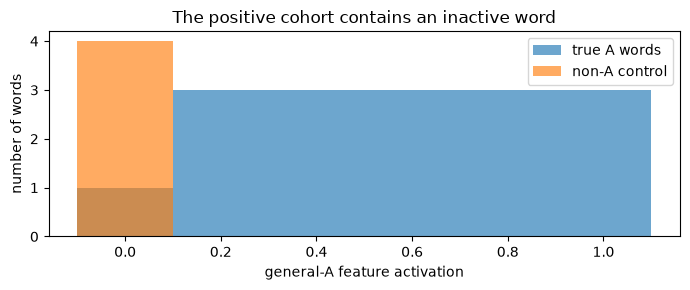

{
  "schema": "arena.feature-dashboard.study.v1",
  "feature": 0,
  "label": "starts with A",
  "n_examples": 8,
  "n_active": 3,
  "examples": [
    {
      "text": "apricot",
      "activation": 1.0
    },
    {
      "text": "ant",
      "activation": 1.0
    },
    {
      "text": "avocado",
      "activation": 1.0
    },
    {
      "text": "apple",
      "activation": 0.0
    },
    {
      "text": "banana",
      "activation": 0.0
    },
    {
      "text": "berry",
      "activation": 0.0
    },
    {
      "text": "boat",
      "activation": 0.0
    },
    {
      "text": "bean",
      "activation": 0.0
    }
  ]
}
precision/recall (1.0, 0.75)


In [20]:
record=dashboard_record(0,"starts with A",WORDS,Z_wide[:,0],k=8)
assert validate_dashboard(record)
display(pd.DataFrame(record["examples"]))
fig,ax=plt.subplots(figsize=(7,3))
ax.hist(Z_wide[labels,0],bins=[-.1,.1,1.1],alpha=.65,label="true A words")
ax.hist(Z_wide[~labels,0],bins=[-.1,.1,1.1],alpha=.65,label="non-A control")
ax.set(xlabel="general-A feature activation",ylabel="number of words",title="The positive cohort contains an inactive word");ax.legend();fig.tight_layout();plt.show()
serialized=json.dumps(record,indent=2,allow_nan=False)
print(serialized)
print("precision/recall",precision_recall(Z_wide[:,0],labels))

<details>
<summary>Help - how should I interpret this?</summary>

The full example list exposes apple at zero. The positive histogram has one zero and three ones; the non-A control has four zeros. A service UI can improve browsing, but it cannot supply the missing causal argument. The JSON remains local text; this cell does not upload or write files.

</details>

## Try it yourself

Forecast the effect of adding `azure` and `applejack` before calculating their codes. Which is missed by the wide general-A feature, and why? Then change only the encoder subtraction coefficient from −1 to −0.5: does partial general-A activation fix the dashboard recall while changing sparsity or reconstruction? Keep the original cohort result intact and label these changes exploratory.

In [21]:
play_words=["apple","azure","applejack","berry"]
play_X=word_properties(play_words)
play_E=E_wide.copy();play_E[2,0]=-.5
play_codes=encode_relu(play_X,play_E,np.zeros(3))
display(pd.DataFrame({"word":play_words,"original general A":encode_relu(play_X,E_wide,np.zeros(3))[:,0],"edited general A":play_codes[:,0],"unrelated B control":play_codes[:,1]}))

,word,original general A,edited general A,unrelated B control
0,apple,0.0,0.5,0.0
1,azure,1.0,1.0,0.0
2,applejack,1.0,1.0,0.0
3,berry,0.0,0.0,1.0


## Interpreting the result

The label was not wholly wrong: every active example began with A. It was incomplete, and a width-three reconstruction hid that incompleteness behind an apple-specific direction. Causal group ablation recovers the broad task contribution. This is a representation counterexample, not a demonstration that increasing trained dictionary width always worsens interpretability.

## Limitations

| Topic | Taught here | Not covered here |
| --- | --- | --- |
| Feature splitting and absorption | Exact first-letter splitting/absorption candidate, precision/recall, overlap and causal group removal | Learned dictionaries across width/sparsity, matched training and a language-model first-letter cohort |
| Attention-output SAE | Concatenated-head encoder contributions and decoder effects through `W_O` and `W_U` | Actual attention-output SAE hook/cache parity, residual normalization and downstream nonlinear effects |
| Feature dashboards | Histogram, top words, label audit, direct task effect and falsifying ablation | A trained-feature case with independent held-out simulation |
| Neuronpedia and sae-vis | Offline JSON-compatible record and explicit consumer mapping boundary | Version-pinned Neuronpedia import/export and sae-vis renderer integration; no live service or format parity claimed |

An attention-output SAE may target concatenated `hook_z`, projected attention outputs or another site. Record the exact site, normalization, head ordering and decoder convention before transferring formulas. A direct logit effect does not include later layers. Error-preserving ablation can still create off-manifold inputs.

# ☆ Bonus

## Anomaly hunt

Could two features cover the same concept with opposite decoder effects? Could high Jaccard overlap hide a sign reversal? Construct a two-feature example and predict an ablation before calculating it. For a trained bridge, freeze the first-letter labels and threshold before inspecting missed positives; retain failures instead of selecting only “nice” features.

## Further reading

- [Chanin et al., A is for Absorption](https://arxiv.org/abs/2409.14507): first-letter ground truth, splitting and absorption in trained SAEs.
- [Kissane et al., Interpreting Attention Layer Outputs with Sparse Autoencoders](https://arxiv.org/abs/2406.17759): attention-output feature interpretation and head analysis.
- [Official attention-output SAE code](https://github.com/ckkissane/attention-output-saes): exact hook and projection conventions.
- [sae-vis](https://github.com/callummcdougall/sae_vis): inspect the installed version's dataset and visualization interfaces.
- [Neuronpedia documentation](https://docs.neuronpedia.org/): distinguish exported public records from versioned service endpoints.